# DS5345 - Aprendizaje por Refuerzo

## Laboratorio 12D: El Algoritmo Dreamer — World Models Latentes e Imaginación

**Docente:** Percy W. Lovon Ramos  
**Semana 12 · Sesión D** (Completado y ejecutado)

---

### Objetivos de la Sesión:

1. **Comprender la Observabilidad Parcial Visual (POMDP):** Trabajar sobre `VisualPendulumEnv`, donde la imagen $32 \times 32$ contiene solo el ángulo $\theta$, requiriendo que la memoria temporal recurrente ($h_t$) infiera la velocidad angular $\dot{\theta}$.
2. **Implementar el Recurrent State-Space Model (RSSM):** Combinar memoria determinística $h_t = \text{GRU}(h_{t-1}, z_{t-1}, a_{t-1})$ con latentes estocásticos $z_t$ (Posterior $q(z_t|h_t, o_t)$ y Prior $p(z_t|h_t)$).
3. **Latent Imagination (Planificación sin Renderizar):** Desplegar trayectorias $H=8..12$ pasos utilizando **únicamente el Prior** y retropropagar gradientes analíticos hacia la política continua del Actor $\pi_\theta(h_t, z_t)$ mediante retornos $V_\lambda$.
4. **Upgrade a DreamerV2 (Reto):** Reemplazar latentes continuos Gaussianos por variables categóricas discretas con **Straight-Through Gradients** y **KL Balancing asimétrico** ($\alpha = 0.8$).
5. **Conexión con DreamerV3:** Comprender el rol de 1% Unimix, Free Bits y transformaciones `symlog` para estabilidad universal.


In [1]:
import time
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import gymnasium as gym
import matplotlib.pyplot as plt

# Limitar hilos evita sobrecoste en estas redes pequeñas en CPU.
torch.set_num_threads(min(4, os.cpu_count() or 1))
print(f"PyTorch {torch.__version__}; hilos: {torch.get_num_threads()}")

# Fijar semillas para reproducibilidad
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")

PyTorch 2.13.0+cpu; hilos: 4
Usando dispositivo: cpu


---

## T1: Entorno POMDP Visual (`VisualPendulumEnv`) y Sequence Replay Buffer

En robótica y videojuegos visuales, un único frame estático no define un estado markoviano: una imagen del péndulo muestra hacia dónde apunta el brazo, pero **no sabemos si gira en sentido horario o antihorario**.
Implementamos un renderizador vectorial ultrarrápido que genera imágenes en escala de grises de $32 \times 32$ con valores normalizados en $[-0.5, 0.5]$ (formato estándar de Dreamer).


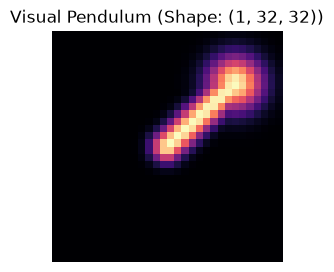

In [ ]:
class VisualPendulumEnv:
    """
    Envuelve Pendulum-v1 (g=2.0) convirtiendo el estado fisico [cos(theta), sin(theta), theta_dot]
    en una imagen 32x32 en escala de grises (1, 32, 32) centrada en [-0.5, 0.5].
    Oculta la velocidad angular theta_dot -> Verdadero POMDP visual.
    """

    def __init__(self, img_size=32, action_repeat=2, g=2.0):
        self.env = gym.make("Pendulum-v1", g=g)
        self.img_size = img_size
        self.action_repeat = action_repeat
        self.action_space = self.env.action_space
        coords = np.linspace(-1.2, 1.2, img_size, dtype=np.float32)
        self.grid_y, self.grid_x = np.meshgrid(coords, coords, indexing="ij")

    def _render_angle(self, cos_th, sin_th):
        tip_x = sin_th
        tip_y = -cos_th
        px, py = self.grid_x, self.grid_y
        proj = np.clip(px * tip_x + py * tip_y, 0.0, 1.0)
        dist_rod = np.sqrt((px - proj * tip_x) ** 2 + (py - proj * tip_y) ** 2)
        dist_bob = np.sqrt((px - tip_x) ** 2 + (py - tip_y) ** 2)
        dist_pivot = np.sqrt(px**2 + py**2)

        rod = np.exp(-0.5 * (dist_rod / 0.11) ** 2)
        bob = np.exp(-0.5 * (dist_bob / 0.20) ** 2)
        pivot = 0.6 * np.exp(-0.5 * (dist_pivot / 0.10) ** 2)
        img = np.clip(np.maximum(np.maximum(rod, bob), pivot), 0.0, 1.0)
        return (img[np.newaxis, :, :] - 0.5).astype(np.float32)

    def reset(self, seed=None):
        self.env.reset(seed=seed)
        rng = np.random.default_rng(seed)
        th = rng.uniform(-1.5, 1.5)
        thdot = rng.uniform(-1.0, 1.0)
        self.env.unwrapped.state = np.array([th, thdot], dtype=np.float32)
        obs = np.array([np.cos(th), np.sin(th), thdot], dtype=np.float32)
        return self._render_angle(obs[0], obs[1]), obs

    def step(self, action):
        u = float(np.clip(action, -2.0, 2.0)[0])
        for _ in range(self.action_repeat):
            obs, _, _, _, _ = self.env.step([u])
        th, thdot = self.env.unwrapped.state
        th_norm = ((th + np.pi) % (2 * np.pi)) - np.pi
        # Recompensa alineada con el nuevo estado alcanzado
        r_new = -(th_norm**2 + 0.15 * (thdot**2) + 0.02 * (u**2)) / 5.0
        return self._render_angle(obs[0], obs[1]), float(r_new), False, obs


class SequenceReplayBuffer:
    """Almacena secuencias completas y muestrea sub-secuencias (B, L, 1, 32, 32)."""

    def __init__(self, capacity_episodes=300):
        self.episodes = []
        self.capacity = capacity_episodes

    def add_episode(self, obs_list, act_list, rew_list):
        ep = {
            "obs": np.array(obs_list, dtype=np.float32),  # (T, 1, 32, 32)
            "act": np.array(act_list, dtype=np.float32),  # (T, 1)
            "rew": np.array(rew_list, dtype=np.float32),  # (T, 1)
        }
        if len(self.episodes) >= self.capacity:
            self.episodes.pop(0)
        self.episodes.append(ep)

    def sample(self, batch_size=16, seq_len=10):
        obs_b, act_b, rew_b = [], [], []
        for _ in range(batch_size):
            ep = self.episodes[np.random.randint(len(self.episodes))]
            T = len(ep["rew"])
            start = np.random.randint(0, T - seq_len + 1)
            obs_b.append(ep["obs"][start : start + seq_len])
            act_b.append(ep["act"][start : start + seq_len])
            rew_b.append(ep["rew"][start : start + seq_len])
        return (
            torch.tensor(np.array(obs_b), device=device),
            torch.tensor(np.array(act_b), device=device),
            torch.tensor(np.array(rew_b), device=device),
        )


# Visualizar un frame de prueba
test_env = VisualPendulumEnv(32, 2)
sample_frame, _ = test_env.reset(seed=42)
plt.figure(figsize=(3, 3))
plt.imshow(sample_frame[0] + 0.5, cmap="magma", vmin=0, vmax=1)
plt.title(f"Visual Pendulum (Shape: {sample_frame.shape})")
plt.axis("off")
plt.show()

---

## T2: World Model Base (DreamerV1: CNN Encoder/Decoder + RSSM Gaussiano)

Las tres ecuaciones fundamentales del RSSM (Teoría Slides 33–34):

1. **Memoria Determinística:** $h_t = f_\varphi(h_{t-1}, z_{t-1}, a_{t-1}) = \text{GRU}(h_{t-1}, \text{MLP}([z_{t-1}, a_{t-1}]))$
2. **Prior (Transición sin imagen):** $p_\varphi(\hat{z}_t \mid h_t) = \mathcal{N}(\mu_p(h_t), \sigma_p^2(h_t))$
3. **Posterior (Inferencia con imagen):** $q_\varphi(z_t \mid h_t, e_t) = \mathcal{N}(\mu_q(h_t, e_t), \sigma_q^2(h_t, e_t))$


In [ ]:
class ConvEncoder(nn.Module):
    """Comprime imagen (1, 32, 32) -> embedding e_t (embed_dim=64)."""

    def __init__(self, embed_dim=64):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=4, stride=2, padding=1),
            nn.ELU(),
            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),
            nn.ELU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.ELU(),
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, embed_dim),
            nn.ELU(),
        )

    def forward(self, obs):
        return self.conv(obs)


class ConvDecoder(nn.Module):
    """Reconstruye imagen (1, 32, 32) en [-0.5, 0.5] desde (h_t, z_t)."""

    def __init__(self, state_dim, stoch_dim):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(state_dim + stoch_dim, 64 * 4 * 4), nn.ELU())
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ELU(),
            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1),
            nn.ELU(),
            nn.ConvTranspose2d(16, 1, kernel_size=4, stride=2, padding=1),
        )

    def forward(self, h, z):
        x = self.fc(torch.cat([h, z], dim=-1)).view(-1, 64, 4, 4)
        return self.deconv(x)


class GaussianRSSM(nn.Module):
    """DreamerV1 RSSM con latentes continuos Gaussianos y truco de reparametrizacion."""

    def __init__(self, action_dim=1, deter_dim=64, stoch_dim=16, embed_dim=64):
        super().__init__()
        self.deter_dim = deter_dim
        self.stoch_dim = stoch_dim
        self.input_proj = nn.Sequential(
            nn.Linear(stoch_dim + action_dim, deter_dim), nn.ELU()
        )
        self.gru = nn.GRUCell(deter_dim, deter_dim)
        self.prior_net = nn.Sequential(
            nn.Linear(deter_dim, 64), nn.ELU(), nn.Linear(64, 2 * stoch_dim)
        )
        self.post_net = nn.Sequential(
            nn.Linear(deter_dim + embed_dim, 64), nn.ELU(), nn.Linear(64, 2 * stoch_dim)
        )
        self.reward_head = nn.Sequential(
            nn.Linear(deter_dim + stoch_dim, 64), nn.ELU(), nn.Linear(64, 1)
        )

    def init_state(self, batch_size):
        return (
            torch.zeros(batch_size, self.deter_dim, device=device),
            torch.zeros(batch_size, self.stoch_dim, device=device),
        )

    def _get_dist(self, stats):
        mu, raw_std = torch.chunk(stats, 2, dim=-1)
        std = F.softplus(raw_std) + 0.1
        return mu, std

    def sample_reparam(self, mu, std):
        return mu + std * torch.randn_like(std)

    def observe_step(self, prev_h, prev_z, prev_a, embed_t):
        x = self.input_proj(torch.cat([prev_z, prev_a], dim=-1))
        h_t = self.gru(x, prev_h)
        prior_mu, prior_std = self._get_dist(self.prior_net(h_t))
        post_mu, post_std = self._get_dist(
            self.post_net(torch.cat([h_t, embed_t], dim=-1))
        )
        z_t = self.sample_reparam(post_mu, post_std)
        return h_t, z_t, (prior_mu, prior_std), (post_mu, post_std)

    def imagine_step(self, prev_h, prev_z, prev_a):
        x = self.input_proj(torch.cat([prev_z, prev_a], dim=-1))
        h_t = self.gru(x, prev_h)
        prior_mu, prior_std = self._get_dist(self.prior_net(h_t))
        z_t = self.sample_reparam(prior_mu, prior_std)
        return h_t, z_t

    def kl_loss(self, post_params, prior_params, free_nats=0.1):
        mu_q, std_q = post_params
        mu_p, std_p = prior_params
        kl = (
            torch.log(std_p / std_q)
            + (std_q**2 + (mu_q - mu_p) ** 2) / (2 * std_p**2)
            - 0.5
        )
        kl = kl.sum(dim=-1).mean()
        return torch.clamp(kl, min=free_nats)


print("GaussianRSSM inicializado correctamente.")

GaussianRSSM inicializado correctamente.


---

## T3: Fase 2 — Imaginación Latente y Actor-Critic (`TODO 1` y `TODO 2`)

En la Fase 2, el agente optimiza su política $\pi_\theta$ **soñando en el espacio latente** sin decodificar imágenes hacia píxeles.

- **`TODO 1` (`imagine_rollout`):** Realiza un despliegue de $H$ pasos partiendo de $(h_0, z_0)$ usando exclusivamente `rssm.imagine_step` y prediciendo recompensas $\hat{r}_\tau = R_\varphi(h_\tau, z_\tau)$.
- **`TODO 2` (`compute_lambda_returns`):** Calcula los retornos $\lambda$ recursivos de Dreamer (Ecuación 6 de Hafner et al., ICLR 2020):
  $$V_\lambda(s_\tau) = \hat{r}_\tau + \gamma \Big( (1 - \lambda) V_\psi(s_{\tau+1}) + \lambda V_\lambda(s_{\tau+1}) \Big), \quad \text{con } V_\lambda(s_H) = V_\psi(s_H)$$


In [ ]:
class Actor(nn.Module):
    def __init__(self, feat_dim, action_dim=1, max_action=2.0):
        super().__init__()
        self.max_action = max_action
        self.net = nn.Sequential(
            nn.Linear(feat_dim, 64),
            nn.ELU(),
            nn.Linear(64, 64),
            nn.ELU(),
            nn.Linear(64, 2 * action_dim),
        )

    def forward(self, feat, deterministic=False):
        mu, raw_std = torch.chunk(self.net(feat), 2, dim=-1)
        if deterministic:
            return self.max_action * torch.tanh(mu)
        std = F.softplus(raw_std) + 0.1
        return self.max_action * torch.tanh(mu + std * torch.randn_like(std))


class Critic(nn.Module):
    def __init__(self, feat_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(feat_dim, 64),
            nn.ELU(),
            nn.Linear(64, 64),
            nn.ELU(),
            nn.Linear(64, 1),
        )

    def forward(self, feat):
        return self.net(feat)


def imagine_rollout(rssm, actor, h_init, z_init, horizon=8):
    """
    TODO 1: Despliega H pasos en el espacio latente usando SOLO rssm.imagine_step.

    Instrucciones:
    1. Inicia h, z con h_init, z_init.
    2. En cada paso de tau=0..horizon-1:
       a. Concatena [h, z] para formar el feature del estado actual.
       b. Obtén la acción con actor(feat).
       c. Avanza el modelo con h, z = rssm.imagine_step(h, z, action).
       d. Concatena el nuevo feature y predice la recompensa latente con rssm.reward_head(next_feat).
       e. Guarda next_feat, reward y action.
    3. Retorna tensores apilados: feats (H, B, D), rewards (H, B, 1), actions (H, B, A).
    """
    h, z = h_init, z_init
    feats, rewards, actions = [], [], []
    for _ in range(horizon):
        action = actor(torch.cat([h, z], dim=-1))
        h, z = rssm.imagine_step(h, z, action)
        feat = torch.cat([h, z], dim=-1)
        feats.append(feat)
        rewards.append(rssm.reward_head(feat))
        actions.append(action)
    return torch.stack(feats), torch.stack(rewards), torch.stack(actions)


def compute_lambda_returns(rewards, values, gamma=0.96, lam=0.92):
    """
    TODO 2: Calcula los retornos V_lambda(s_tau) recursivamente desde tau=H-1 hasta 0:
      V_lambda(s_t) = rewards[t] + gamma * ((1 - lam) * values[t] + lam * next_val)
      donde next_val se inicializa con values[-1].
    """
    next_val = values[-1]
    returns = []
    for t in reversed(range(rewards.shape[0])):
        next_val = rewards[t] + gamma * ((1 - lam) * values[t] + lam * next_val)
        returns.append(next_val)
    return torch.stack(returns[::-1])

---

## T4: Reto de Implementación — Upgrade a DreamerV2 (`TODO 3` y `TODO 4`)

En **DreamerV2** (Hafner et al., ICLR 2021), los latentes continuos Gaussianos se reemplazan por **$K$ variables categóricas con $C$ clases cada una** ($K=8, C=8 \implies 64\text{D}$):

1. **`TODO 3` (`sample_categorical_straight_through`):**
   - Convierte los logits en probabilidades softmax y mezcla con **1% Unimix**:
     $$p = 0.99 \cdot \text{softmax}(\text{logits}) + 0.01 \cdot \frac{1}{C}$$
   - Muestrea de `torch.distributions.OneHotCategorical`.
   - Aplica el **Straight-Through Estimator (Algorithm 1)** para permitir el flujo de gradientes hacia los logits:
     $$z = \text{one\_hot} + p - \text{sg}(p)$$
2. **`TODO 4` (`kl_loss`):**
   - Implementa **KL Balancing asimétrico (Algorithm 2)** con $\alpha = 0.8$:
     $$\mathcal{L}_{\text{KL}} = \alpha \cdot \text{KL}[\text{sg}(\text{post}) \parallel \text{prior}] + (1 - \alpha) \cdot \text{KL}[\text{post} \parallel \text{sg}(\text{prior})]$$


In [ ]:
class CategoricalRSSM(nn.Module):
    """DreamerV2 RSSM con latentes discretos categoricos (K=8, C=8), Straight-Through y KL Balancing."""

    def __init__(
        self, action_dim=1, deter_dim=64, num_cats=8, num_classes=8, embed_dim=64
    ):
        super().__init__()
        self.deter_dim = deter_dim
        self.num_cats = num_cats
        self.num_classes = num_classes
        self.stoch_dim = num_cats * num_classes  # 64
        self.input_proj = nn.Sequential(
            nn.Linear(self.stoch_dim + action_dim, deter_dim), nn.ELU()
        )
        self.gru = nn.GRUCell(deter_dim, deter_dim)
        self.prior_net = nn.Sequential(
            nn.Linear(deter_dim, 64), nn.ELU(), nn.Linear(64, self.stoch_dim)
        )
        self.post_net = nn.Sequential(
            nn.Linear(deter_dim + embed_dim, 64),
            nn.ELU(),
            nn.Linear(64, self.stoch_dim),
        )
        self.reward_head = nn.Sequential(
            nn.Linear(deter_dim + self.stoch_dim, 64), nn.ELU(), nn.Linear(64, 1)
        )

    def init_state(self, batch_size):
        return (
            torch.zeros(batch_size, self.deter_dim, device=device),
            torch.zeros(batch_size, self.stoch_dim, device=device),
        )

    def sample_categorical_straight_through(self, logits, unimix=0.01):
        """
        TODO 3: Muestreo categorico con 1% Unimix y Straight-Through Gradients.

        Instrucciones:
        1. Reshape logits a (B, K, C).
        2. Aplica softmax sobre la dimension de clases C.
        3. Mezcla con 1% uniforme: (1 - unimix) * probs + unimix / C.
        4. Muestrea one_hot con torch.distributions.OneHotCategorical(probs=probs).sample().
        5. Aplica Straight-Through Estimator:
             z_kc = one_hot + probs - probs.detach()
        6. Aplana a (B, K*C) y retorna (z_flat, probs).
        """
        logits = logits.reshape(-1, self.num_cats, self.num_classes)
        probs = F.softmax(logits, dim=-1)
        probs = (1 - unimix) * probs + unimix / self.num_classes
        one_hot = torch.distributions.OneHotCategorical(probs=probs).sample()
        z = one_hot + (probs - probs.detach())
        return z.reshape(-1, self.stoch_dim), probs

    def observe_step(self, prev_h, prev_z, prev_a, embed_t):
        x = self.input_proj(torch.cat([prev_z, prev_a], dim=-1))
        h_t = self.gru(x, prev_h)
        prior_logits = self.prior_net(h_t)
        post_logits = self.post_net(torch.cat([h_t, embed_t], dim=-1))
        z_t, post_probs = self.sample_categorical_straight_through(post_logits)
        _, prior_probs = self.sample_categorical_straight_through(prior_logits)
        return h_t, z_t, prior_probs, post_probs

    def imagine_step(self, prev_h, prev_z, prev_a):
        x = self.input_proj(torch.cat([prev_z, prev_a], dim=-1))
        h_t = self.gru(x, prev_h)
        prior_logits = self.prior_net(h_t)
        z_t, _ = self.sample_categorical_straight_through(prior_logits)
        return h_t, z_t

    def kl_loss(self, post_probs, prior_probs, alpha=0.8, free_nats=0.1):
        """
        TODO 4: KL Balancing asimetrico (Algorithm 2 de Hafner et al. 2021).

        Instrucciones:
        1. Define funcion auxiliar _kl(p, q) = sum_{K,C} p * (log(p+eps) - log(q+eps)).
        2. Calcula kl_dyn = _kl(post_probs.detach(), prior_probs)  # Entrena al Prior
        3. Calcula kl_rep = _kl(post_probs, prior_probs.detach())  # Regulariza al Posterior
        4. Retorna alpha * kl_dyn + (1 - alpha) * kl_rep
        """

        def _kl(p, q):
            return (
                (p * (p.clamp_min(1e-8).log() - q.clamp_min(1e-8).log()))
                .sum(dim=(-2, -1))
                .mean()
            )

        kl_dyn = _kl(post_probs.detach(), prior_probs).clamp_min(free_nats)
        kl_rep = _kl(post_probs, prior_probs.detach()).clamp_min(free_nats)
        return alpha * kl_dyn + (1 - alpha) * kl_rep

In [ ]:
# Comprobaciones pequeñas antes del entrenamiento completo.
rewards_test = torch.tensor([1.0, 2.0, 3.0], device=device).view(3, 1, 1)
values_test = torch.tensor([10.0, 20.0, 30.0], device=device).view(3, 1, 1)
assert torch.allclose(
    compute_lambda_returns(rewards_test, values_test, 0.5, 0),
    rewards_test + 0.5 * values_test,
)
assert torch.allclose(
    compute_lambda_returns(rewards_test, values_test, 0.5, 1).flatten(),
    torch.tensor([6.5, 11.0, 18.0], device=device),
)
print(
    "Retornos λ=1 (ejemplo):",
    compute_lambda_returns(rewards_test, values_test, 0.5, 1).flatten().tolist(),
)
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(SEED)
    for cls in (GaussianRSSM, CategoricalRSSM):
        model = cls().to(device)
        policy = Actor(model.deter_dim + model.stoch_dim).to(device)
        for param in model.parameters():
            param.requires_grad_(False)
        features, rewards, actions = imagine_rollout(
            model, policy, *model.init_state(2), horizon=8
        )
        assert features.shape == (8, 2, model.deter_dim + model.stoch_dim)
        assert rewards.shape == (8, 2, 1) and actions.shape == (8, 2, 1)
        (-rewards.mean()).backward()
        grad = sum(
            p.grad.abs().sum().item() for p in policy.parameters() if p.grad is not None
        )
        assert grad > 0 and all(p.grad is None for p in model.parameters())
        print(
            f"{cls.__name__}: features={tuple(features.shape)}, gradiente actor L1={grad:.6f}"
        )
    model = CategoricalRSSM().to(device)
    logits = torch.randn(2, 64, device=device, requires_grad=True)
    z, probs = model.sample_categorical_straight_through(logits)
    assert torch.allclose(z.view(2, 8, 8).sum(-1), torch.ones(2, 8, device=device))
    assert ((z == 0) | (z == 1)).all() and probs.min() >= 0.01 / 8
    (z * torch.arange(64, device=device)).sum().backward()
    assert logits.grad.abs().sum() > 0
    print("Categorías: one-hot válido; gradiente ST no nulo; mínimo Unimix=0.00125")
    for alpha in (0.8, 0.1):
        q_logits = torch.zeros(2, 8, 8, device=device, requires_grad=True)
        p_logits = torch.zeros(2, 8, 8, device=device, requires_grad=True)
        with torch.no_grad():
            q_logits[..., 0] = 2
        q, p = q_logits.softmax(-1), p_logits.softmax(-1)
        loss = model.kl_loss(q, p, alpha=alpha, free_nats=0)
        gq, gp = torch.autograd.grad(loss, (q_logits, p_logits))
        print(
            f"α={alpha}: KL={loss.item():.4f}, |grad prior|={gp.norm().item():.4f}, |grad posterior|={gq.norm().item():.4f}"
        )
print("Todas las comprobaciones pasaron.")

Retornos λ=1 (ejemplo): [6.5, 11.0, 18.0]
GaussianRSSM: features=(8, 2, 80), gradiente actor L1=1.841759
CategoricalRSSM: features=(8, 2, 128), gradiente actor L1=0.235367
Categorías: one-hot válido; gradiente ST no nulo; mínimo Unimix=0.00125
α=0.8: KL=3.5201, |grad prior|=0.6646, |grad posterior|=0.2137
α=0.1: KL=3.5201, |grad prior|=0.0831, |grad posterior|=0.9614
Todas las comprobaciones pasaron.


---

## Entrenamiento y Comparativa Experimental: DreamerV1 vs DreamerV2

Ejecutamos el entrenamiento de ambas variantes en `VisualPendulumEnv` por 140 iteraciones (el tiempo medido aparece en el output):

1. **Fase 1 (World Model):** Supervisión de imágenes y recompensas con ELBO.
2. **Fase 2 (Imaginación):** Rollouts latentes $H=8$ y actualización analítica del Actor-Critic.
3. **Fase 3 (Interacción Real):** Cada 10 iteraciones, el agente actúa en el entorno real recolectando datos frescos para el buffer.


In [ ]:
def run_experiment(version="v1", n_iters=140):
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    env = VisualPendulumEnv(img_size=32, action_repeat=2, g=2.0)
    buffer = SequenceReplayBuffer(capacity_episodes=250)

    for ep in range(15):
        obs, state = env.reset(seed=SEED + ep)
        obs_l, act_l, rew_l = [], [], []
        for _ in range(40):
            if ep < 8:
                act = np.random.uniform(-2.0, 2.0, size=(1,)).astype(np.float32)
            else:
                th = np.arctan2(state[1], state[0])
                act = np.clip(
                    [-2.0 * th - 0.5 * state[2] + np.random.normal(0, 0.5)], -2.0, 2.0
                ).astype(np.float32)
            next_obs, r, done, state = env.step(act)
            obs_l.append(next_obs)
            act_l.append(act)
            rew_l.append([r])
        buffer.add_episode(obs_l, act_l, rew_l)

    encoder = ConvEncoder(embed_dim=64).to(device)
    if version == "v1":
        rssm = GaussianRSSM(action_dim=1, deter_dim=64, stoch_dim=16, embed_dim=64).to(
            device
        )
    else:
        rssm = CategoricalRSSM(
            action_dim=1, deter_dim=64, num_cats=8, num_classes=8, embed_dim=64
        ).to(device)

    feat_dim = rssm.deter_dim + rssm.stoch_dim
    decoder = ConvDecoder(rssm.deter_dim, rssm.stoch_dim).to(device)
    actor = Actor(feat_dim, action_dim=1, max_action=2.0).to(device)
    critic = Critic(feat_dim).to(device)

    wm_params = (
        list(encoder.parameters())
        + list(rssm.parameters())
        + list(decoder.parameters())
    )
    wm_opt = optim.Adam(wm_params, lr=2e-3)
    actor_opt = optim.Adam(actor.parameters(), lr=1e-3)
    critic_opt = optim.Adam(critic.parameters(), lr=1e-3)

    history = {"recon_loss": [], "rew_loss": [], "kl_loss": [], "eval_returns": []}

    def evaluate_policy():
        eval_rets = []
        for s in [101, 102, 103, 104, 105]:
            obs, _ = env.reset(seed=s)
            h, z = rssm.init_state(1)
            prev_a = torch.zeros(1, 1, device=device)
            ep_ret = 0.0
            for _ in range(40):
                with torch.no_grad():
                    obs_t = torch.tensor(obs[np.newaxis], device=device)
                    emb_t = encoder(obs_t)
                    h, z, _, _ = rssm.observe_step(h, z, prev_a, emb_t)
                    feat = torch.cat([h, z], dim=-1)
                    act_t = actor(feat, deterministic=True)
                    act_np = act_t.cpu().numpy()[0]
                obs, r, done, _ = env.step(act_np)
                ep_ret += r * 5.0
                prev_a = act_t
                if done:
                    break
            eval_rets.append(ep_ret)
        return float(np.mean(eval_rets))

    history["eval_returns"].append(evaluate_policy())

    for it in range(1, n_iters + 1):
        obs_b, act_b, rew_b = buffer.sample(batch_size=16, seq_len=10)
        B, L = obs_b.shape[0], obs_b.shape[1]
        embeds = encoder(obs_b.view(B * L, 1, 32, 32)).view(B, L, -1)

        h, z = rssm.init_state(B)
        hs, zs, kl_total = [], [], 0.0

        for t in range(L):
            h, z, prior_p, post_p = rssm.observe_step(h, z, act_b[:, t], embeds[:, t])
            hs.append(h)
            zs.append(z)
            kl_total = kl_total + rssm.kl_loss(post_p, prior_p, free_nats=0.1)

        hs_stack = torch.stack(hs, dim=1)
        zs_stack = torch.stack(zs, dim=1)
        feats_flat = torch.cat([hs_stack, zs_stack], dim=-1).view(B * L, -1)

        recon_obs = decoder(hs_stack.view(B * L, -1), zs_stack.view(B * L, -1)).view(
            B, L, 1, 32, 32
        )
        pred_rew = rssm.reward_head(feats_flat).view(B, L, 1)

        recon_loss = (
            F.mse_loss(recon_obs, obs_b, reduction="none").sum(dim=(2, 3, 4)).mean()
        )
        rew_loss = F.mse_loss(pred_rew, rew_b)
        kl_loss = kl_total / L
        wm_loss = recon_loss + 25.0 * rew_loss + 0.2 * kl_loss

        wm_opt.zero_grad()
        wm_loss.backward()
        nn.utils.clip_grad_norm_(wm_params, 10.0)
        wm_opt.step()

        # Fase 2: Latent Imagination
        with torch.no_grad():
            h_start = hs_stack.detach().reshape(B * L, -1)
            z_start = zs_stack.detach().reshape(B * L, -1)

        for p in wm_params:
            p.requires_grad_(False)
        imag_feats, imag_rews, imag_acts = imagine_rollout(
            rssm, actor, h_start, z_start, horizon=8
        )
        for p in critic.parameters():
            p.requires_grad_(False)
        imag_vals = critic(imag_feats)
        lambda_rets = compute_lambda_returns(imag_rews, imag_vals, gamma=0.96, lam=0.92)

        actor_loss = -lambda_rets.mean()
        actor_opt.zero_grad()
        actor_loss.backward()
        nn.utils.clip_grad_norm_(actor.parameters(), 10.0)
        actor_opt.step()

        for p in wm_params:
            p.requires_grad_(True)
        for p in critic.parameters():
            p.requires_grad_(True)
        critic_vals = critic(imag_feats.detach())
        critic_loss = F.mse_loss(critic_vals, lambda_rets.detach())
        critic_opt.zero_grad()
        critic_loss.backward()
        nn.utils.clip_grad_norm_(critic.parameters(), 10.0)
        critic_opt.step()

        history["recon_loss"].append(float(recon_loss.item()))
        history["rew_loss"].append(float(rew_loss.item()))
        history["kl_loss"].append(float(kl_loss.item()))

        if it % 10 == 0:
            obs, _ = env.reset(seed=SEED + 200 + it)
            h_e, z_e = rssm.init_state(1)
            prev_a_e = torch.zeros(1, 1, device=device)
            obs_l, act_l, rew_l = [], [], []
            for _ in range(40):
                with torch.no_grad():
                    obs_t = torch.tensor(obs[np.newaxis], device=device)
                    emb_t = encoder(obs_t)
                    h_e, z_e, _, _ = rssm.observe_step(h_e, z_e, prev_a_e, emb_t)
                    feat_e = torch.cat([h_e, z_e], dim=-1)
                    act_t = actor(feat_e, deterministic=False)
                    act_np = np.clip(
                        act_t.cpu().numpy()[0] + np.random.normal(0, 0.15, size=(1,)),
                        -2.0,
                        2.0,
                    ).astype(np.float32)
                next_obs, r, done, _ = env.step(act_np)
                obs_l.append(next_obs)
                act_l.append(act_np)
                rew_l.append([r])
                obs = next_obs
                prev_a_e = torch.tensor(act_np[np.newaxis], device=device)
                if done:
                    break
            buffer.add_episode(obs_l, act_l, rew_l)

        if it % 20 == 0:
            history["eval_returns"].append(evaluate_policy())

    env.env.close()
    return encoder, rssm, decoder, actor, critic, buffer, history


t0 = time.time()
enc1, rssm1, dec1, act1, crit1, buf1, hist1 = run_experiment("v1", n_iters=140)
enc2, rssm2, dec2, act2, crit2, buf2, hist2 = run_experiment("v2", n_iters=140)
print(f"Experimentos completados en {time.time() - t0:.2f}s")

Experimentos completados en 38.95s


---

### Inspección Visual de Sueños en Lazo Abierto (Open-Loop Trajectory Dreaming)

Alimentamos **4 pasos de contexto real** (actualizando con el Posterior $q(z_t|h_t, o_t)$) y luego **cerramos los ojos por 8 pasos**, dejando que el agente imagine el futuro **únicamente con el Prior $p(z_t|h_t)$**:


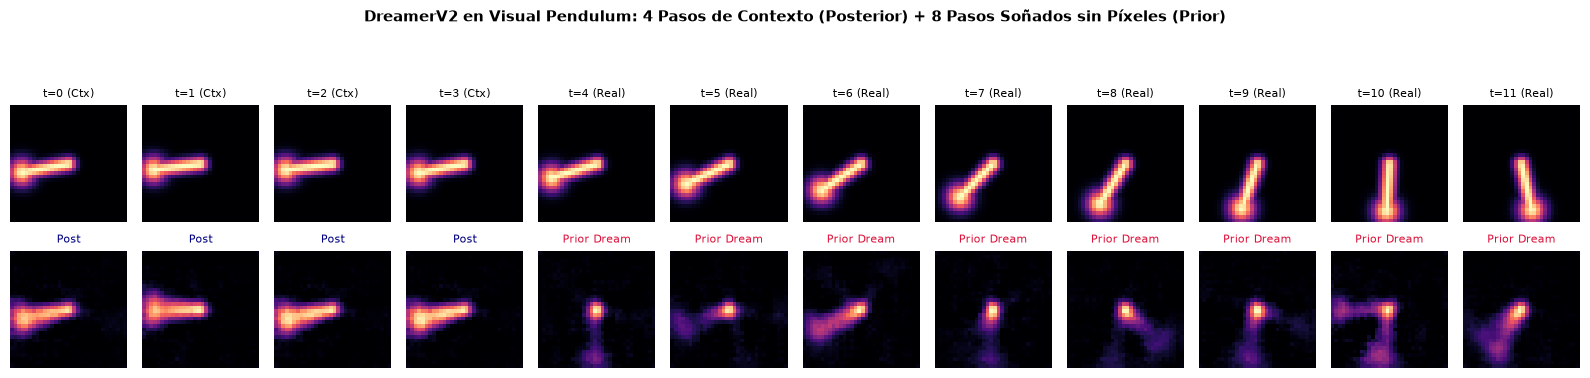

In [ ]:
# Decodificar suenos en lazo abierto con DreamerV2
obs_seq, act_seq, _ = buf2.sample(batch_size=1, seq_len=12)
with torch.no_grad():
    embeds = enc2(obs_seq[0])
    h, z = rssm2.init_state(1)
    prev_a = torch.zeros(1, 1, device=device)
    pred_imgs = []
    for t in range(12):
        # El buffer guarda (o_{t+1}, a_t, r_{t+1}): usar la acción de la misma fila.
        prev_a = act_seq[0, t : t + 1]
        if t < 4:
            h, z, _, _ = rssm2.observe_step(h, z, prev_a, embeds[t : t + 1])
        else:
            h, z = rssm2.imagine_step(h, z, prev_a)
        recon = dec2(h, z)[0, 0].cpu().numpy() + 0.5
        pred_imgs.append(np.clip(recon, 0.0, 1.0))

fig, axes = plt.subplots(2, 12, figsize=(16, 4))
for t in range(12):
    real_im = obs_seq[0, t, 0].cpu().numpy() + 0.5
    axes[0, t].imshow(real_im, cmap="magma", vmin=0, vmax=1)
    axes[0, t].axis("off")
    axes[0, t].set_title(f"t={t}" + (" (Ctx)" if t < 4 else " (Real)"), fontsize=8)
    axes[1, t].imshow(pred_imgs[t], cmap="magma", vmin=0, vmax=1)
    axes[1, t].axis("off")
    axes[1, t].set_title(
        "Post" if t < 4 else "Prior Dream",
        fontsize=8,
        color="navy" if t < 4 else "crimson",
    )
plt.suptitle(
    "DreamerV2 en Visual Pendulum: 4 Pasos de Contexto (Posterior) + 8 Pasos Soñados sin Píxeles (Prior)",
    fontsize=11,
    fontweight="bold",
)
plt.tight_layout(rect=(0, 0, 1, 0.90), h_pad=2.0)
plt.show()

---

### Curvas de Aprendizaje: DreamerV1 (Gaussiano) vs DreamerV2 (Categórico + KL Balancing)


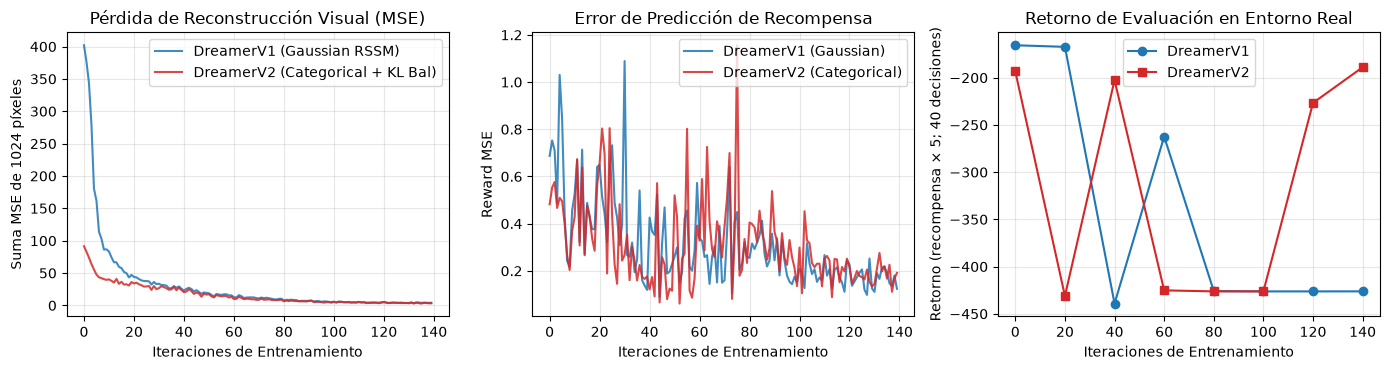

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
axs[0].plot(
    hist1["recon_loss"], label="DreamerV1 (Gaussian RSSM)", color="#1f77b4", alpha=0.85
)
axs[0].plot(
    hist2["recon_loss"],
    label="DreamerV2 (Categorical + KL Bal)",
    color="#d62728",
    alpha=0.85,
)
axs[0].set_title("Pérdida de Reconstrucción Visual (MSE)")
axs[0].set_xlabel("Iteraciones de Entrenamiento")
axs[0].set_ylabel("Suma MSE de 1024 píxeles")
axs[0].legend()
axs[0].grid(alpha=0.3)

axs[1].plot(
    hist1["rew_loss"], label="DreamerV1 (Gaussian)", color="#1f77b4", alpha=0.85
)
axs[1].plot(
    hist2["rew_loss"], label="DreamerV2 (Categorical)", color="#d62728", alpha=0.85
)
axs[1].set_title("Error de Predicción de Recompensa")
axs[1].set_xlabel("Iteraciones de Entrenamiento")
axs[1].set_ylabel("Reward MSE")
axs[1].legend()
axs[1].grid(alpha=0.3)

iters_eval = [0] + list(range(20, 141, 20))
axs[2].plot(iters_eval, hist1["eval_returns"], "-o", label="DreamerV1", color="#1f77b4")
axs[2].plot(iters_eval, hist2["eval_returns"], "-s", label="DreamerV2", color="#d62728")
axs[2].set_title("Retorno de Evaluación en Entorno Real")
axs[2].set_xlabel("Iteraciones de Entrenamiento")
axs[2].set_ylabel("Retorno (recompensa × 5; 40 decisiones)")
axs[2].legend()
axs[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Resumen numérico para interpretar las curvas sin leer valores a ojo.
print(
    "Variante | Recon inicial → final | Reward MSE inicial → final | KL final | Retorno inicial → final"
)
for name, hist in [("V1", hist1), ("V2", hist2)]:
    assert all(np.isfinite(hist[k]).all() for k in hist)
    print(
        f"{name} | {hist['recon_loss'][0]:.4f} → {hist['recon_loss'][-1]:.4f} | "
        f"{hist['rew_loss'][0]:.4f} → {hist['rew_loss'][-1]:.4f} | "
        f"{hist['kl_loss'][-1]:.4f} | {hist['eval_returns'][0]:.2f} → {hist['eval_returns'][-1]:.2f}"
    )
real_imgs = obs_seq[0, :, 0].cpu().numpy() + 0.5
dream_mse = ((np.array(pred_imgs) - real_imgs) ** 2).mean(axis=(1, 2))
print("V2 MSE por píxel, contexto (4):", np.round(dream_mse[:4], 4))
print("V2 MSE por píxel, prior (8):", np.round(dream_mse[4:], 4))

Variante | Recon inicial → final | Reward MSE inicial → final | KL final | Retorno inicial → final
V1 | 402.0284 → 4.0471 | 0.6871 → 0.1238 | 16.9505 | -165.61 → -426.23
V2 | 91.4964 → 3.2983 | 0.4820 → 0.1912 | 7.3588 | -193.36 → -188.91
V2 MSE por píxel, contexto (4): [0.0012 0.0051 0.0033 0.0013]
V2 MSE por píxel, prior (8): [0.0391 0.0209 0.0119 0.0333 0.0378 0.0224 0.0223 0.0464]


### Lectura de los resultados guardados

En esta ejecución, V1 redujo la reconstrucción de **402.0284 a 4.0471**, pero su retorno empeoró de **−165.61 a −426.23**. V2 redujo la reconstrucción de **91.4964 a 3.2983**, con retorno de **−193.36 a −188.91**. V2 terminó mejor entre estas dos corridas; su mejora respecto a su propio inicio fue pequeña. Una buena reconstrucción no garantiza una política útil, y las pérdidas iniciales distintas también reflejan inicializaciones y capacidades diferentes.

Los sueños del prior presentan error apreciable respecto a los frames reales. No hay evaluación del modelo en un conjunto hold-out, múltiples semillas de entrenamiento ni ablación de α: las gráficas y cifras son evidencia descriptiva de esta demostración, no una conclusión general sobre DreamerV1/V2. Las respuestas Q1–Q4 citan los outputs de esta ejecución; al cambiar parámetros o volver a ejecutar, deben actualizarse las cifras comentadas.


### Q1. Observabilidad Parcial (POMDP) y Reparto de Trabajo en el RSSM

¿Por qué una sola imagen $32 \times 32$ de `VisualPendulumEnv` viola la propiedad de Markov? Explica cómo se reparten el trabajo $h_t$ y $z_t$ en el RSSM cuando cortamos la observación en $t \ge 4$.

> **Respuesta del Estudiante:**  
> Una imagen muestra el ángulo, pero no la velocidad: el mismo frame puede corresponder a giros opuestos con futuros diferentes. $h_t$ resume el historial de imágenes y acciones; $z_t$ representa información estocástica condicionada por esa memoria. Desde $t\ge4$, $h_t$ evoluciona con la GRU y $z_t$ se muestrea del prior, sin correcciones del posterior. En el sueño guardado, el MSE por píxel medio pasa de 0.0027 en los cuatro frames de contexto a 0.0293 en los ocho del prior: ilustra la limitación predictiva de esta trayectoria, no una prueba directa de que se haya aprendido la velocidad.


### Q2. Truco de Reparametrización vs Straight-Through Gradients

Compara el truco de reparametrización continuo (DreamerV1) con el Straight-Through Estimator discreto (DreamerV2). ¿Por qué los latentes categóricos son superiores en dominios con transiciones multimodales?

> **Respuesta del Estudiante:**  
> V1 usa $z=\mu+\sigma\epsilon$, diferenciable respecto a los parámetros para ruido fijo. V2 muestrea one-hot en el forward y usa la derivada de las probabilidades en el backward: es un estimador sesgado. Las categorías pueden representar alternativas separadas sin imponer una única Gaussiana; el paper V2 plantea esto como explicación posible de sus ventajas en transiciones multimodales, no como superioridad universal. Las pruebas dieron gradientes no nulos del actor (1.841759 en V1 y 0.235367 en V2) y categorías one-hot válidas. El retorno final fue −426.23 vs −188.91, pero una corrida, capacidades distintas y varios cambios simultáneos no permiten atribuir esa diferencia solo a los latentes.


### Q3. KL Balancing Asimétrico ($\alpha = 0.8$)

En el `TODO 4`, minimizamos $\mathcal{L}_{\text{KL}} = \alpha \cdot \text{KL}[\text{sg}(\text{post}) \parallel \text{prior}] + (1 - \alpha) \cdot \text{KL}[\text{post} \parallel \text{sg}(\text{prior})]$. ¿Qué sucedería si invirtiéramos los pesos utilizando $\alpha = 0.1$?

> **Respuesta del Estudiante:**  
> Con $\alpha=0.1$, el prior recibe peso 0.1 y el posterior 0.9: se favorece adaptar la representación a un prior todavía imperfecto, con riesgo de perder información y empeorar la imaginación. La prueba con las mismas distribuciones y sin suelo KL conserva la pérdida 3.5201, pero la norma del gradiente del prior baja de 0.6646 a 0.0831 y la del posterior sube de 0.2137 a 0.9614. Cambia la dirección de aprendizaje por rama; no se entrenó una política completa con α=0.1.


### Q4. MBPO vs Dreamer: Comparativa Arquitectónica

Contrasta MBPO (Sesión 12C) con Dreamer (Sesión 12D): ¿En qué espacio genera los rollouts cada algoritmo y cómo calcula cada uno el gradiente para actualizar al Actor?

> **Respuesta del Estudiante:**  
> MBPO genera transiciones cortas en el espacio de estados observados y las mezcla con datos reales para un algoritmo off-policy (SAC en MBPO original): el actor se actualiza mediante el crítico, sin retropropagar a través del rollout del modelo. el Lab12C usa una Q-network y selección argmax, por lo que allí no existe un actor separado. Dreamer imagina en $(h,z)$ y deriva el retorno λ a través del prior, recompensas y valores hasta el actor. Las pruebas anteriores muestran rollouts de forma (8, 2, 80) y (8, 2, 128), y gradientes del actor no nulos con el modelo congelado. No se ejecutó MBPO para una comparación numérica.


---

## Bonus (DreamerV3): Transformación Symlog / Symexp

DreamerV3 (Hafner et al., Nature) introduce la compresión simétrica logarítmica para permitir que los mismos hiperparámetros funcionen en entornos con escalas de recompensa dispares (desde 0.001 hasta 100,000):
$$\text{symlog}(x) = \text{sign}(x) \cdot \ln(|x| + 1), \qquad \text{symexp}(y) = \text{sign}(y) \cdot (\exp(|y|) - 1)$$


In [ ]:
def symlog(x):
    return torch.sign(x) * torch.log1p(torch.abs(x))


def symexp(y):
    return torch.sign(y) * torch.expm1(torch.abs(y))


# Verificacion de biyeccion symexp(symlog(x)) == x
test_x = torch.tensor([-1000.0, -10.0, -0.5, 0.0, 0.5, 10.0, 1000.0])
compressed = symlog(test_x)
restored = symexp(compressed)

print("Valores originales:  ", test_x.numpy())
print("Comprimidos (symlog):", np.round(compressed.numpy(), 3))
print("Restaurados (symexp):", np.round(restored.numpy(), 3))
assert torch.allclose(restored, test_x, atol=1e-4), "Error en transformacion inversa"

Valores originales:   [-1.e+03 -1.e+01 -5.e-01  0.e+00  5.e-01  1.e+01  1.e+03]
Comprimidos (symlog): [-6.909 -2.398 -0.405  0.     0.405  2.398  6.909]
Restaurados (symexp): [-1.e+03 -1.e+01 -5.e-01  0.e+00  5.e-01  1.e+01  1.e+03]
